<div style="background-color:rgb(100, 110, 220); padding:10px;">

## Day 3: Feature Engineering and Classification Basics
- **Data Preprocessing**
  - **Feature Engineering**
    - Creating new features -- Interaction terms and domain-specific features
    - Discretization/Binning
    - Encoding categorical variables
- **Machine Learning Algorithms**
  - Introduction to Classification (Logistic Regression)
- **Model Selection and Evaluation**
  - Performance Metrics for Classification (Accuracy, Precision, Recall, F1-Score)


### Dataset: weatherHistory.csv, poro-perm.csv, wines_binary.csv
### libraries: pandas, scikit learn, matplotlib, and seaborn


# 1. Data Preprocessing

## 1.1. Feature enginearing

Feature engineering is the process of transforming raw data into meaningful features that better represent the underlying problem to predictive models, resulting in improved model accuracy. This includes discritization, creating new features, and encoding.

🚫If a transformation uses statistics from the data (e.g., bin edges learned from quantiles), compute them on the training data only.

### 1.1.1 Discritize/bining 
Discretization involves dividing continuous features into discrete bins or intervals. This can be particularly useful for simplifying models or when dealing with features that naturally fall into categories.

- Simplifies the model by reducing the number of unique values a feature can take.
- Helps in reducing the noise in data.
- Can make models more interpretable.
- Non-linear relationships (trees don’t need it; linear models might benefit).
- Robustness to outliers.
- Interpretability (e.g., risk bands).

- Discretization should be used thoughtfully, as it can sometimes lead to loss of information.
- The choice of bin intervals should be guided by domain knowledge or data distribution.


**Example: Converting a continuous age feature into age groups like 0-18, 19-35, 36-60, and 60+.**

👉 <a href="https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.cut.html">Pandas <code>cut()</code> documentation</a>

In [1]:
import pandas as pd
df = pd.read_csv('../Lecture_data/weatherHistory_train_Val.csv')
df = df.dropna()

df['Temp_Bin'] = pd.cut(df['Temperature (C)'], bins=[-10, 0, 10, 20, 30, 40], labels=['-10 to 0', '0 to 10', '10 to 20', '20 to 30', '30 to 40'])

In [2]:
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary,Temp_Bin
0,2006-08-14 18:00:00.000 +0200,Partly Cloudy,rain,22.477778,22.477778,0.58,10.8192,159.0,11.1251,0.0,Mostly cloudy until night.,20 to 30
1,2006-08-15 10:00:00.000 +0200,Partly Cloudy,rain,21.061111,21.061111,0.73,7.7924,264.0,11.2056,0.0,Partly cloudy until evening.,20 to 30
2,2006-08-17 12:00:00.000 +0200,Clear,rain,28.838889,29.611111,0.51,9.6600,177.0,9.9820,0.0,Partly cloudy until morning.,20 to 30
3,2006-08-18 09:00:00.000 +0200,Clear,rain,24.950000,24.950000,0.69,16.0195,180.0,9.9015,0.0,Partly cloudy starting overnight continuing un...,20 to 30
4,2006-08-22 18:00:00.000 +0200,Partly Cloudy,rain,23.811111,23.811111,0.45,16.0195,290.0,11.2056,0.0,Partly cloudy starting in the morning.,20 to 30


Other methods:
- Fixed (domain) bins: manual edges (safe pre-split because they don’t learn from data).
- Equal-width bins: divide the numeric range into k equal intervals.
- Equal-frequency (quantile) bins
- KBinsDiscretizer (sklearn): strategy="uniform" | "quantile" | "kmeans" **Excercises**
In the fixed-bin example, `pd.cut` uses intervals open on the left and closed on the right. Values outside the supplied boundaries become missing; extend the outer boundaries if every temperature should receive a bin.


### 1.1.2 Creating New Features
Creating new features involves using existing data to generate additional features that could improve model performance. This can include applying transformations, creating interaction terms, or generating domain-specific features.

- Transformations: Applying mathematical transformations like logarithmic or exponential functions to features.
- Interaction Terms: Creating new features by combining two or more existing features (e.g., multiplying temperature by humidity). It is important to be cautious about multicollinearity, which can arise when the original features are highly correlated with the new interaction term. To mitigate this, we can either: Drop the original features used to create the interaction term, or use models that incorporate regularization, such as Ridge or Lasso regression, to reduce the risk of overfitting.


- Domain-Specific Features: Features that are derived based on specific knowledge of the domain.

🚫Create features from X only. If a feature uses y (target) to compute values, that is leakage

### 1.1.3. Encoding Categorical features and/or target
### Why encoding?
* Data may be represented as words, letters, or symbols 
* Most Machine Learning algorithms only process numerical data


#### One-Hot Encoding
**Description**: Converts categorical variables into a series of binary columns, each representing a unique category.

**Example**: For a feature "Color" with values ["Red", "Green", "Blue"], one-hot encoding would create three new columns: "Color_Red", "Color_Green", and "Color_Blue", with binary values indicating the presence of each color.

| Color  | Color_Red | Color_Green | Color_Blue |
|--------|-----------|-------------|------------|
| Red    | 1         | 0           | 0          |
| Green  | 0         | 1           | 0          |
| Blue   | 0         | 0           | 1          |


⚠️ **Watch Cardinality**:  
> One-hot encoding can explode the number of columns if a feature has high cardinality (e.g., >50–100 categories).  
> Before applying it, check how many unique values exist. If the number is large, consider:
> - Grouping rare levels into an `"Other"` category
> - Using frequency or count encoding
> - Applying the hashing trick see FQA
> - target/mean encoding see FQA (this is leackage prone if not done appropriately)

#### Ordinal Encoding — only if there’s a true order
When: categories have a meaningful order (e.g., None < Low < Medium < High).

#### Label Encoding 
**Description**: Assigns a unique integer to each category.

**Example**: For the same "Color" feature, label encoding would assign integers to each category.

| Color  | Encoded_Color |
|--------|----------------|
| Red    | 0              |
| Green  | 1              |
| Blue   | 2              |

* 👉 <a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html">Sklearn <code>LabelEncoder()</code> documentation</a>

⚠️ generally avoid on for feature encoding usually used for target. introduces a fake order. you feed into tree models that split by thresholds and you accept the arbitrary order (even then, OHE is usually safer).

> It’s generally **not recommended** for feature encoding, especially for non-ordinal categorical variables.  
> Tree-based models may tolerate it (as they split by thresholds), but even then, **one-hot encoding is usually safer**.  
> Label encoding is more commonly used for **target variables**, not features.


In [3]:
df['Precip Type'].value_counts()

Precip Type
rain    81052
snow     7194
Name: count, dtype: int64

In [4]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")  #

type_encoded = ohe.fit_transform(df[['Precip Type']])

ohe.categories_[0]

array(['rain', 'snow'], dtype=object)

In [5]:
encoded_df = pd.DataFrame(type_encoded, columns=ohe.categories_[0], index=df.index)

df_new = pd.concat([df, encoded_df], axis=1)

df_new.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary,Temp_Bin,rain,snow
0,2006-08-14 18:00:00.000 +0200,Partly Cloudy,rain,22.477778,22.477778,0.58,10.8192,159.0,11.1251,0.0,Mostly cloudy until night.,20 to 30,1.0,0.0
1,2006-08-15 10:00:00.000 +0200,Partly Cloudy,rain,21.061111,21.061111,0.73,7.7924,264.0,11.2056,0.0,Partly cloudy until evening.,20 to 30,1.0,0.0
2,2006-08-17 12:00:00.000 +0200,Clear,rain,28.838889,29.611111,0.51,9.6600,177.0,9.9820,0.0,Partly cloudy until morning.,20 to 30,1.0,0.0
3,2006-08-18 09:00:00.000 +0200,Clear,rain,24.950000,24.950000,0.69,16.0195,180.0,9.9015,0.0,Partly cloudy starting overnight continuing un...,20 to 30,1.0,0.0
4,2006-08-22 18:00:00.000 +0200,Partly Cloudy,rain,23.811111,23.811111,0.45,16.0195,290.0,11.2056,0.0,Partly cloudy starting in the morning.,20 to 30,1.0,0.0


# 2. Machine Learning Algorithms: Introduction to Classification

### 2.1 Understanding Classification
Classification is a type of supervised learning where the goal is to predict a categorical label for a given input. Unlike regression, where the output is a continuous value, classification outputs discrete labels, such as "spam" or "not spam," "disease" or "no disease," etc.

#### Types of Classification:
- **Binary Classification**: The simplest form of classification where there are only two possible outcomes (e.g., 0 or 1, true or false). Many scikit-learn classifiers also accept text labels. If numeric labels are needed, use a consistent mapping such as the following.

```
y_train_cls = (y_train == "positive_label").astype(int)
y_test_cls  = (y_test  == "positive_label").astype(int)

```


- **Multi-Class Classification**: Where there are more than two possible classes, and each input is assigned to one of these classes. Encoding the target: LabelEncoder

```
le = LabelEncoder()
y_train_cls = le.fit_transform(y_train)   # fit on TRAIN
y_test_cls  = le.transform(y_test)       # transform TEST
```


- **Multi-Label Classification**: Where each input can be assigned to multiple labels (e.g., tagging multiple objects in an image). Encoding the target :MultiLabelBinarizer
- 
```
mlb = MultiLabelBinarizer()
y_train_bin = mlb.fit_transform(y_train_list_of_sets)
y_test_bin  = mlb.transform(y_test_list_of_sets)

```

<div style="background-color:rgba(60, 179, 113, 0.3); padding:10px;">


### 2.2 Logistic Regression
Logistic Regression is one of the most common algorithms used for binary classification problems. Despite its name, it’s a linear model for classification rather than regression.

#### Key Concepts in Logistic Regression:
- **Logistic Function (Sigmoid Function)**: The logistic function maps any real-valued number into the range [0, 1]. It is defined as:

  $$
  \sigma(z) = \frac{1}{1 + e^{-z}}
  $$

  This function is used to estimate the probability that a given input belongs to a certain class.

- **Decision Boundary**: Logistic regression applies a threshold (usually 0.5) to the output of the logistic function to classify inputs into one of the two classes. If the predicted probability is greater than 0.5, the input is classified as 1 (positive class); otherwise, it is classified as 0 (negative class).
</div>
tive class).

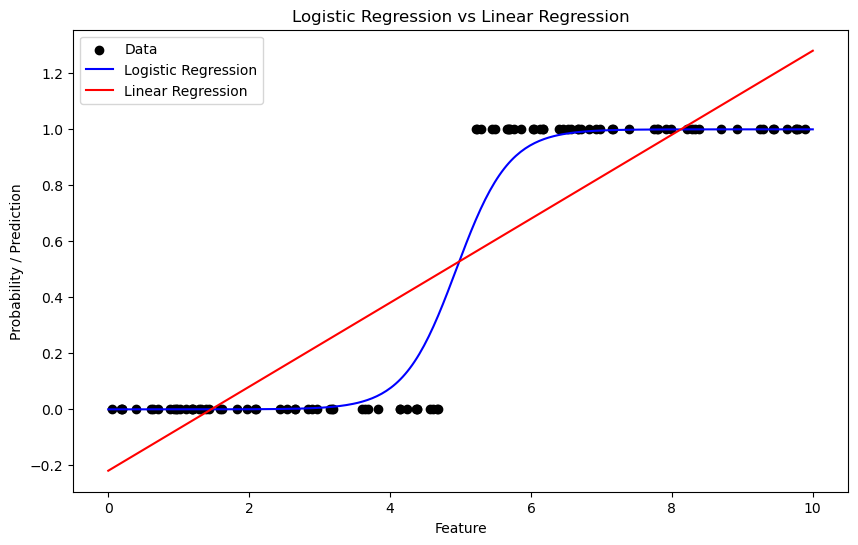

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
np.random.seed(0)
X = np.random.rand(100, 1) * 10  # Feature
y = (X > 5).astype(int).ravel()  # Binary target

log_reg = LogisticRegression()
log_reg.fit(X, y)

lin_reg = LinearRegression()
lin_reg.fit(X, y)

X_test = np.linspace(0, 10, 300).reshape(-1, 1)
log_pred = log_reg.predict_proba(X_test)[:, 1]
lin_pred = lin_reg.predict(X_test)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='black', label='Data')
plt.plot(X_test, log_pred, color='blue', label='Logistic Regression')
plt.plot(X_test, lin_pred, color='red', label='Linear Regression')
plt.xlabel('Feature')
plt.ylabel('Probability / Prediction')
plt.title('Logistic Regression vs Linear Regression')
plt.legend()
plt.show()


In [6]:
##### --------------------------- The minimum required steps ---------------------
## this is without EDA, checking data type and feature engineering
import pandas as pd
df = pd.read_csv('../Lecture_data/wines_binary.csv')
df.head()
df.duplicated().sum()
y = df['is_good_quality']
X = df.drop(columns=['is_good_quality'])
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
missing = X_train.isnull().sum() / len(X_train)
missing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
##### --------------------------- The minimum required steps ---------------------

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

## 🔧 Hyperparameters

In scikit-learn’s `LogisticRegression` model, several hyperparameters control the behavior, regularization, and optimization of the model. Here’s a breakdown of the most important ones, including options for multiclass classification:

### penalty
Specifies the type of regularization to apply:
- `'l2'` (default): L2 regularization.
- `'l1'`: L1 regularization (only supported with solvers `'liblinear'` or `'saga'`).
- `'elasticnet'`: ElasticNet regularization (only supported with `'saga'` solver). Requires setting `l1_ratio`.
- `'none'`: No regularization, useful for simple or small datasets.

### C
Controls the strength of regularization, with smaller values implying stronger regularization. This parameter is the inverse of regularization strength, so lower values lead to more shrinkage of coefficients.

### solver
Specifies the algorithm for optimization:
- `'liblinear'`: Suitable for small datasets; supports L1 regularization.
- `'saga'`: Scalable for larger datasets and supports L1, L2, and ElasticNet regularization.
- `'lbfgs'` and `'newton-cg'`: Suitable for L2 regularization and commonly used for larger datasets.

### max_iter
Sets the maximum number of iterations for the solver to converge. Increase this if the model has trouble converging.

### tol
Sets the tolerance for stopping criteria. Lower values can lead to more accurate solutions but may require more iterations.

### Multiclass Options
- **multi_class**: Determines how the model handles multiclass classification:
  - `'ovr'` (One-vs-Rest) (default): Fits a separate binary classifier for each class.
  - `'multinomial'`: Uses a single model for all classes, supported with `'lbfgs'`, `'saga'`, and `'newton-cg'` solvers. This is often preferred for balanced, multiclass datasets as it directly optimizes for all classes.

**For more see [math_classifications Notes](../Dive_deeper/math_classifications.ipynb)**

**For more see [multiclassification Notes](../Dive_deeper/multiclassification.ipynb) and [multiclassification interactive](../Dive_deeper/Multiclassification.html)**

**For more see [Binary_classification Notes](../Dive_deeper/Binary_classification.html)**




# 3. Performance Metrics for Classification

When evaluating classification models, it’s essential to understand how well the model can predict categorical outcomes.
it's crucial to understand the foundational concepts of True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN).
## 3.1 Confusion Matrix
let's consider binary classification, but this is applicable to the muticlass classification as well.


<img src="../imgs/confusion_matrix.jpg" alt="Description" style="width: 1400px;"/>




### Visual Representation: Confusion Matrix Example

Imagine a binary classification problem where we're predicting whether a patient has a disease (Positive) or not (Negative).

|                  | Predicted Positive | Predicted Negative |
|------------------|--------------------|--------------------|
| **Actual Positive** | 50 (TP)            | 10 (FN)            |
| **Actual Negative** | 5 (FP)             | 100 (TN)           |


- **TP = 50**: The model correctly predicts the positive class. The model correctly identified 50 patients with the disease.
- **TN = 100**: The model correctly predicts the negative class. The model correctly identified 100 patients without the disease.
- **FP = 5**: The model incorrectly predicts the positive class (Type I error). The model incorrectly identified 5 healthy patients as having the disease.
- **FN = 10**: The model incorrectly predicts the negative class (Type II error). The model missed 10 patients who actually have the disease.

## 3.2. Performance Metrics for Classification


| Metric     | Equation                                                                 | When to Use                                                                                     |
|------------|--------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------|
| **Accuracy** | $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$                  | Use when the classes are well balanced and you need a general measure of how often the model is correct. |
| **Precision** | $$\text{Precision} = \frac{TP}{TP + FP}$$                                | Use when the cost of false positives is high (e.g., predicting a person has a disease when they don't). |
| **Recall**    | $$\text{Recall} = \frac{TP}{TP + FN}$$                                  | Use when the cost of false negatives is high (e.g., missing a cancer diagnosis).                     |
| **F1-Score**  | $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$ | Use when you need a balance between Precision and Recall, especially in cases of imbalanced datasets. |

###  Accuracy
- **Example**: In a binary classification where you are predicting whether an email is spam, if the model correctly predicts 90 out of 100 emails, the accuracy is 90%.
- **Limitations**:
  - **Imbalanced Datasets**: Accuracy can be misleading if the dataset is imbalanced. For example, if 95% of the emails are not spam, a model that always predicts "not spam" will have 95% accuracy but is not useful.
  - 🚨Using accuracy alone can give overly confident scores, especially when dealing with imbalanced datasets🚨

### Precision

- **Example**: If a model identifies 10 emails as spam, but only 8 are actually spam, the precision is 0.8 (80%).
- **Limitations**:
  - **Doesn’t Consider False Negatives**: Precision ignores the false negatives, which can be problematic if missing positive cases is critical.

### Recall
- **Example**: If there are 10 actual spam emails and the model correctly identifies 8 of them, the recall is 0.8 (80%).
- **Limitations**:
  - **Doesn’t Consider False Positives**: High recall can be achieved at the cost of a higher number of false positives, which might not be desirable.

###  F1-Score
- **Example**: If a model has a precision of 0.8 and a recall of 0.6, the F1-Score would be approximately 0.685.
- **Limitations**:
  - **Doesn’t Differentiate Between Different Costs**: The F1-Score assumes that Precision and Recall are equally important, which might not always be the case.


In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_pred = lr.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-Score: {f1}")
print(f"Confusion Matrix:\n{conf_matrix}")


Accuracy: 0.8613
Precision: 0.8751557955961778
Recall: 0.8427685537107421
F1-Score: 0.8586568837256701
Confusion Matrix:
[[8800 1202]
 [1572 8426]]


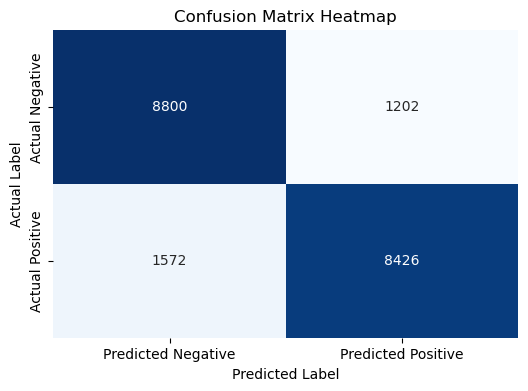

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap')
plt.show()


# FAQ: 

<div style="background-color:rgba(75, 0, 130, 0.3); padding:10px;">

**1. Are there other ways to handle categorical features?**

- **Target encoding** replaces categories with target statistics learned from the training data. Use out-of-fold encodings for training rows and fit the mapping only on training data before transforming validation/test data. Smoothing helps with rare categories but does not itself prevent leakage.
- **Feature hashing** maps category tokens to a fixed set of columns, usually using signed counts. Different tokens can collide. It does not learn arbitrary fractional values for each category.
- **Weight of Evidence (WoE)** compares class-conditional category frequencies. One common convention is $\log[P(\mathrm{category}\mid y=0)/P(\mathrm{category}\mid y=1)]$; the opposite sign convention is also used. This differs from within-category log odds. Fit it on training data with appropriate smoothing and leakage control.
- **Native categorical support** in some boosting libraries learns splits over categories. This is not a separate generic method called "Light G-Boost Encoding."

</div>